# Depth Anything 3 point clouds on CrowdPose

Three single-image, visible-surface point clouds: one annotated person (`100069`),
three people with overlap (`107292`), and eight people in a crowded skatepark
(`100144`). These are *scene* clouds without segmentation or hidden-surface
completion. DA3-BASE predicts relative depth and camera intrinsics; the xyz
coordinates have arbitrary scale, **not meters**.

This notebook deliberately runs on CPU with two threads. It never allocates
CUDA memory, so it can be rerun while the training GPU is busy. The depth
model is `depth-anything/DA3-BASE` at revision
`f4a6c9b3c95e41c82048423d3493a81ec3fa810e`; the official source checkout
used for this execution is commit `3d835ec1a5802d64a8b8b15f817a1ab54809bfe4`.
See the [compatibility report](depth-segmentation-compatibility.md) for other
depth choices and why pretrained DINO segmentation heads do not attach directly
to DA3 features.

For a clean environment, install the
[official DA3 package](https://github.com/ByteDance-Seed/Depth-Anything-3)
in a separate virtual environment and select that environment as the notebook
kernel. This saved execution used the repository's PyTorch environment with
the official checkout and missing DA3 import dependencies placed under local
`tmp/`; it did not modify the active training environment. The checkpoint is
downloaded on first use. Run the notebook from the repository root, or from
its own directory.

The figures show RGBD and RGB-colored views; the official DA3 GLB can be rotated
in a 3D viewer. The NPZ files retain aligned, unfiltered RGBD and camera matrices.


In [1]:
from pathlib import Path
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import display

torch.set_num_threads(2)
torch.set_num_interop_threads(1)
DEVICE = torch.device("cpu")
assert DEVICE.type == "cpu"

ROOT = Path.cwd()
if not (ROOT / "data/crowdpose/images").is_dir():
    ROOT = Path.cwd().parents[1]
assert (ROOT / "data/crowdpose/images").is_dir(), "Run from the repository root or notebook directory"

OUTPUT_DIR = ROOT / "reports/3d-prior/assets"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ID = "depth-anything/DA3-BASE"
MODEL_REVISION = "f4a6c9b3c95e41c82048423d3493a81ec3fa810e"
IMAGE_IDS = [100069, 107292, 100144]
POINT_STRIDE = 3
PROCESS_RESOLUTION = 504

annotation_path = ROOT / "data/crowdpose/annotations/crowdpose_val.json"
annotations = json.loads(annotation_path.read_text())
person_counts = {
    image_id: sum(a["image_id"] == image_id and not a["iscrowd"] for a in annotations["annotations"])
    for image_id in IMAGE_IDS
}
print("Device:", DEVICE, "| CPU threads:", torch.get_num_threads())
print("Annotated people:", person_counts)

Device: cpu | CPU threads: 2
Annotated people: {100069: 1, 107292: 3, 100144: 8}


## Projection, RGBD, and the official exporter

DA3 supplies aligned `processed_images`, `depth`, `conf`, and `intrinsics` at the
processed image resolution. For pixel `(u,v)` at depth `z`, the camera-frame
point is `K⁻¹ [u,v,1] z`; the simplified pinhole equations are
`x=(u-cx)z/fx`, `y=(v-cy)z/fy`, `z=depth`. Camera `y` points down. The
intrinsics below are **estimated by DA3** in processed-image pixel units.

We compare every pixel against DA3's official projection before its GLB
alignment. Confidence filtering follows the official GLB threshold, so the
RGB-colored 3D views and PLY omit the lowest-confidence points. The `.npz`
RGBD files retain the **unfiltered** RGB, depth, confidence, intrinsics, and
extrinsics for re-analysis. The official `.glb` uses glTF axes and centering,
so its coordinates differ from the camera-frame PLY by a rigid transform.


In [2]:
def backproject_rgbd(rgb, depth, intrinsics, stride=1, valid_mask=None):
    if rgb.ndim != 3 or rgb.shape[2] != 3 or depth.shape != rgb.shape[:2]:
        raise ValueError("RGB and depth must have aligned HxW dimensions")
    if intrinsics.shape != (3, 3) or stride < 1:
        raise ValueError("Expected a 3x3 intrinsics matrix and positive stride")

    fx, fy = float(intrinsics[0, 0]), float(intrinsics[1, 1])
    cx, cy = float(intrinsics[0, 2]), float(intrinsics[1, 2])
    if not np.isfinite([fx, fy, cx, cy]).all() or fx <= 0 or fy <= 0:
        raise ValueError("Invalid camera intrinsics")

    rows = np.arange(0, depth.shape[0], stride)
    cols = np.arange(0, depth.shape[1], stride)
    uu, vv = np.meshgrid(cols, rows)
    sampled_depth = depth[::stride, ::stride]
    sampled_rgb = rgb[::stride, ::stride]
    valid = np.isfinite(sampled_depth) & (sampled_depth > 0)
    if valid_mask is not None:
        if valid_mask.shape != depth.shape:
            raise ValueError("Confidence mask must match depth dimensions")
        valid &= valid_mask[::stride, ::stride]
    if not valid.any():
        raise ValueError("Depth has no positive finite samples")

    z = sampled_depth[valid].astype(np.float32)
    x = (uu[valid] - cx) * z / fx
    y = (vv[valid] - cy) * z / fy
    points = np.column_stack((x, y, z)).astype(np.float32)
    colors = sampled_rgb[valid].astype(np.uint8)
    return points, colors


def write_ascii_ply(path, points, colors):
    if len(points) != len(colors):
        raise ValueError("Every point needs one RGB color")
    header = ("ply\nformat ascii 1.0\n"
              f"element vertex {len(points)}\n"
              "property float x\nproperty float y\nproperty float z\n"
              "property uchar red\nproperty uchar green\nproperty uchar blue\n"
              "end_header\n")
    with Path(path).open("w") as file:
        file.write(header)
        np.savetxt(file, np.column_stack((points, colors)),
                   fmt="%.6f %.6f %.6f %d %d %d")


# Synthetic non-square image: pixel (u=2,v=1), z=4, fx=2, fy=4, cx=1, cy=0.
test_rgb = np.zeros((2, 3, 3), dtype=np.uint8)
test_rgb[1, 2] = (255, 20, 10)
test_depth = np.full((2, 3), np.nan, dtype=np.float32)
test_depth[1, 2] = 4
test_K = np.array([[2, 0, 1], [0, 4, 0], [0, 0, 1]], dtype=np.float32)
test_points, test_colors = backproject_rgbd(test_rgb, test_depth, test_K)
np.testing.assert_allclose(test_points, [[2, 1, 4]])
np.testing.assert_array_equal(test_colors, [[255, 20, 10]])
print("Synthetic projection and invalid-depth filtering: passed")

Synthetic projection and invalid-depth filtering: passed


## CPU inference

Each image is inferred separately to keep RAM use bounded. The `504` input
resolution and stride `3` are recorded above. We do not pass multiple images
as a multi-view sequence because the three CrowdPose scenes are unrelated.

The GLB exporter runs on CPU after each prediction.


[WARN ] Dependency `gsplat` is required for rendering 3DGS. Install via: pip install git+https://github.com/nerfstudio-project/gsplat.git@0b4dddf04cb687367602c01196913cde6a743d70


[INFO ] using MLP layer as FFN


Model loaded on cpu
[INFO ] Processed Images Done taking 0.019817590713500977 seconds. Shape:  torch.Size([1, 3, 420, 504])


[INFO ] Model Forward Pass Done. Time: 70.82238411903381 seconds
[INFO ] Conversion to Prediction Done. Time: 0.00033020973205566406 seconds
[INFO ] conf_thresh_percentile: 40.0
[INFO ] num max points: 100000
[INFO ] Exporting to GLB with num_max_points: 100000


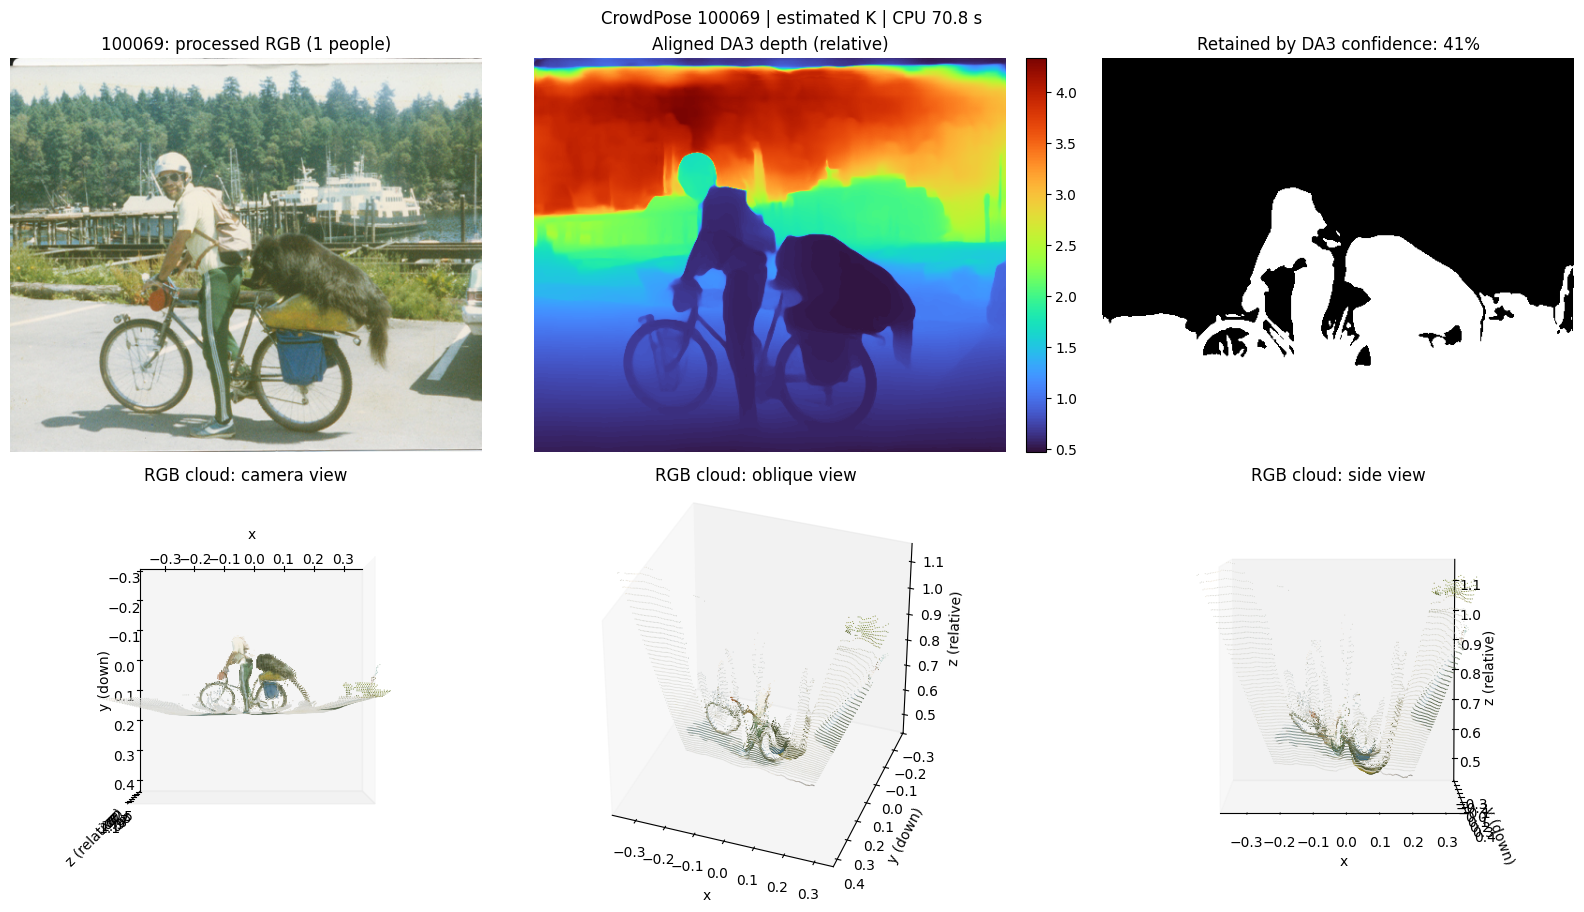

{
  "image_id": 100069,
  "annotated_people": 1,
  "processed_hw": [
    420,
    504
  ],
  "points": 9679,
  "confidence_retained": 0.414,
  "confidence_threshold": 1.05,
  "projection_max_error": 4.76837158203125e-07,
  "depth_min": 0.47414323687553406,
  "depth_max": 4.326952934265137,
  "intrinsics": [
    [
      608.44140625,
      0.0,
      252.0
    ],
    [
      0.0,
      616.553955078125,
      210.0
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "cpu_seconds": 70.8,
  "figure": "reports/3d-prior/assets/100069_da3base_pointcloud.png",
  "rgbd": "reports/3d-prior/assets/100069_da3base_rgbd.npz",
  "ply": "reports/3d-prior/assets/100069_da3base.ply",
  "glb": "reports/3d-prior/assets/100069_da3base_glb/scene.glb"
}
[INFO ] Processed Images Done taking 0.010505199432373047 seconds. Shape:  torch.Size([1, 3, 336, 504])


[INFO ] Model Forward Pass Done. Time: 52.358481645584106 seconds
[INFO ] Conversion to Prediction Done. Time: 0.0003554821014404297 seconds
[INFO ] conf_thresh_percentile: 40.0
[INFO ] num max points: 100000
[INFO ] Exporting to GLB with num_max_points: 100000


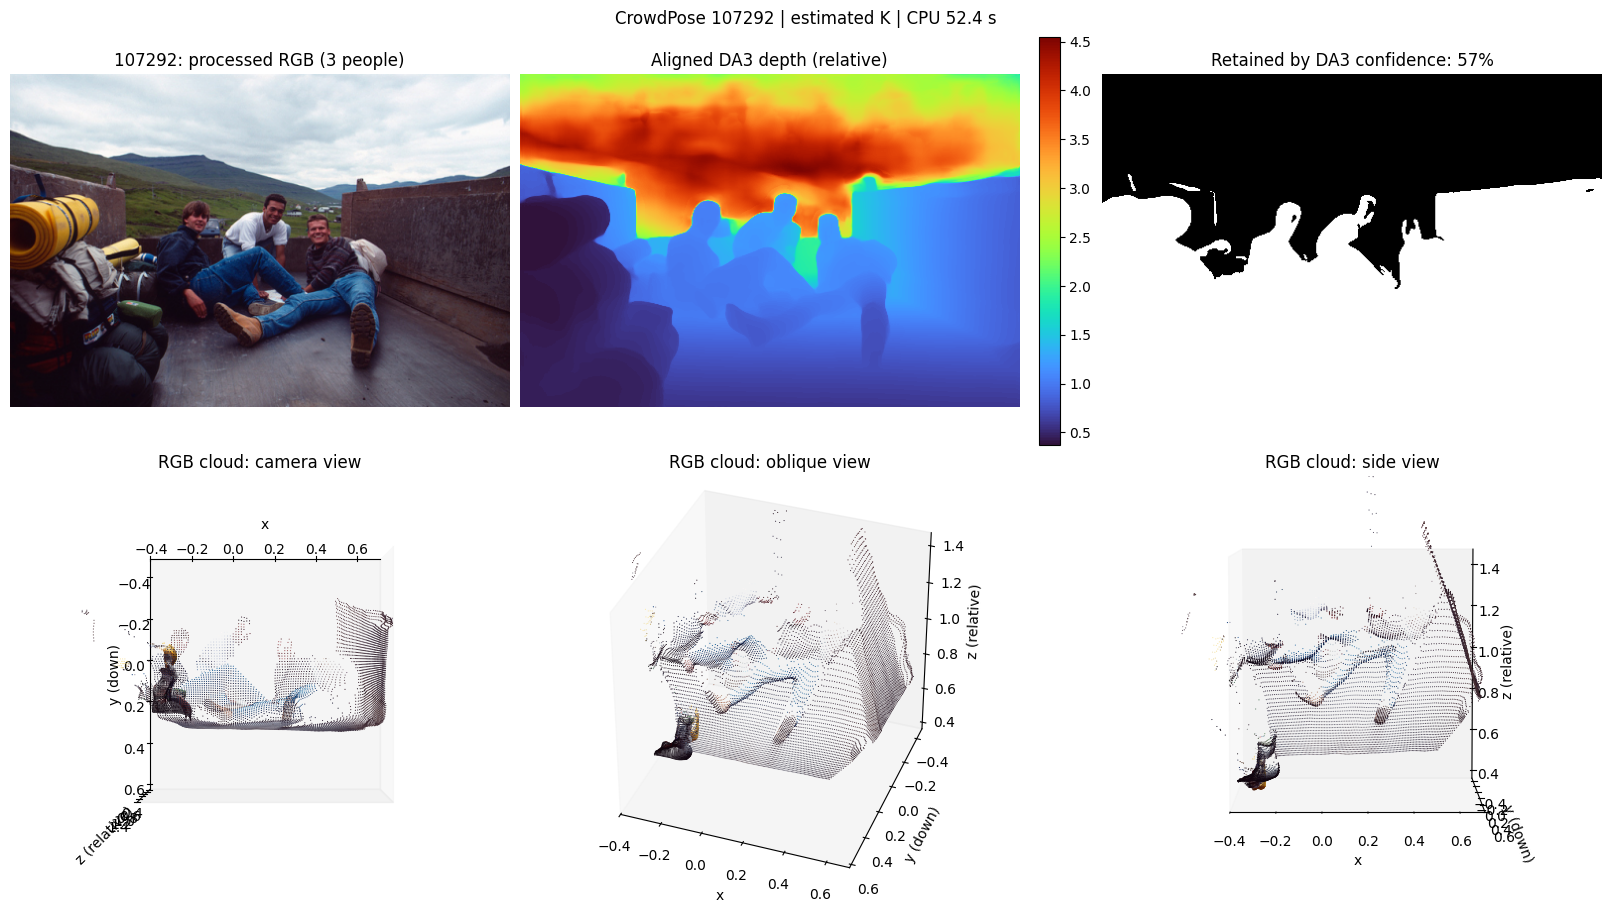

{
  "image_id": 107292,
  "annotated_people": 3,
  "processed_hw": [
    336,
    504
  ],
  "points": 10743,
  "confidence_retained": 0.574,
  "confidence_threshold": 1.05,
  "projection_max_error": 4.76837158203125e-07,
  "depth_min": 0.3752272129058838,
  "depth_max": 4.547499656677246,
  "intrinsics": [
    [
      291.0287780761719,
      0.0,
      252.0
    ],
    [
      0.0,
      292.24072265625,
      168.0
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "cpu_seconds": 52.4,
  "figure": "reports/3d-prior/assets/107292_da3base_pointcloud.png",
  "rgbd": "reports/3d-prior/assets/107292_da3base_rgbd.npz",
  "ply": "reports/3d-prior/assets/107292_da3base.ply",
  "glb": "reports/3d-prior/assets/107292_da3base_glb/scene.glb"
}
[INFO ] Processed Images Done taking 0.0059490203857421875 seconds. Shape:  torch.Size([1, 3, 336, 504])


[INFO ] Model Forward Pass Done. Time: 54.02139925956726 seconds
[INFO ] Conversion to Prediction Done. Time: 0.00025916099548339844 seconds
[INFO ] conf_thresh_percentile: 40.0
[INFO ] num max points: 100000
[INFO ] Exporting to GLB with num_max_points: 100000


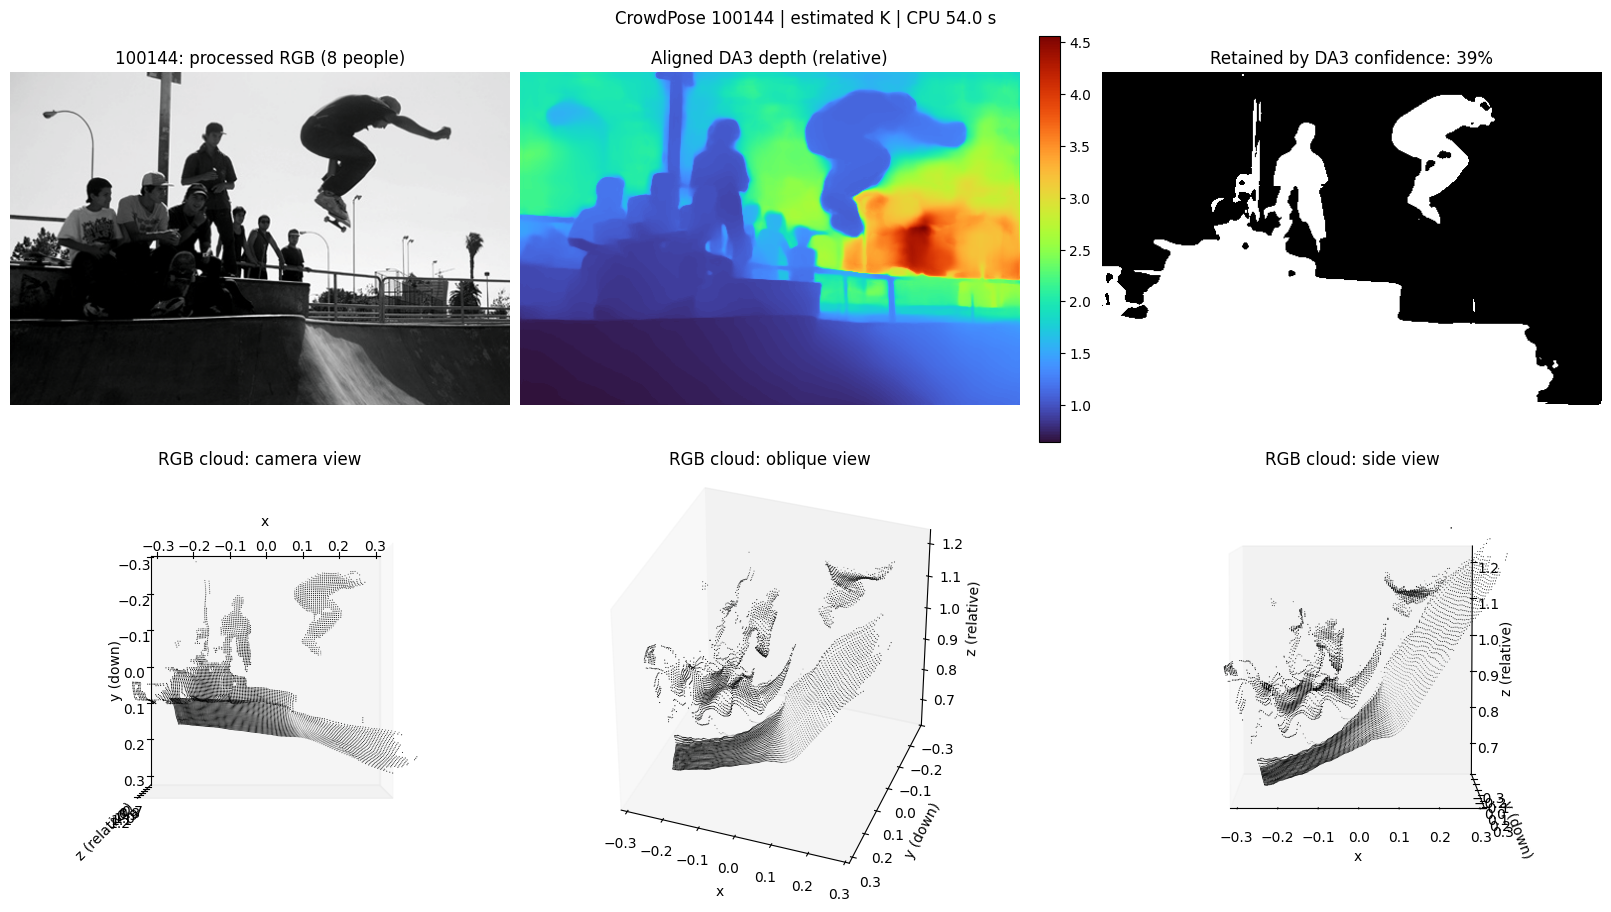

{
  "image_id": 100144,
  "annotated_people": 8,
  "processed_hw": [
    336,
    504
  ],
  "points": 7343,
  "confidence_retained": 0.392,
  "confidence_threshold": 1.05,
  "projection_max_error": 4.76837158203125e-07,
  "depth_min": 0.6465899348258972,
  "depth_max": 4.561508655548096,
  "intrinsics": [
    [
      682.9218139648438,
      0.0,
      252.0
    ],
    [
      0.0,
      683.1297607421875,
      168.0
    ],
    [
      0.0,
      0.0,
      1.0
    ]
  ],
  "cpu_seconds": 54.0,
  "figure": "reports/3d-prior/assets/100144_da3base_pointcloud.png",
  "rgbd": "reports/3d-prior/assets/100144_da3base_rgbd.npz",
  "ply": "reports/3d-prior/assets/100144_da3base.ply",
  "glb": "reports/3d-prior/assets/100144_da3base_glb/scene.glb"
}


In [3]:
from depth_anything_3.api import DepthAnything3
from depth_anything_3.utils.export.glb import (
    _as_homogeneous44,
    _depths_to_world_points_with_colors,
    export_to_glb,
    get_conf_thresh,
)

model = DepthAnything3.from_pretrained(MODEL_ID, revision=MODEL_REVISION).to(DEVICE).eval()
print("Model loaded on", next(model.parameters()).device)


def draw_cloud(ax, points, colors, elevation, azimuth, title):
    ax.scatter(points[:, 0], points[:, 1], points[:, 2],
               c=colors / 255.0, s=2.5, marker=".", linewidths=0,
               depthshade=False, rasterized=True)
    ax.view_init(elev=elevation, azim=azimuth)
    ax.grid(False)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y (down)")
    ax.set_zlabel("z (relative)")
    low = np.percentile(points, 1, axis=0)
    high = np.percentile(points, 99, axis=0)
    center = (low + high) / 2
    span = max(float(np.max(high - low)), 1e-6)
    ax.set_xlim(center[0] - span / 2, center[0] + span / 2)
    ax.set_ylim(center[1] + span / 2, center[1] - span / 2)
    ax.set_zlim(center[2] - span / 2, center[2] + span / 2)
    ax.set_box_aspect((1, 1, 1))


records = []
for image_id in IMAGE_IDS:
    image_path = ROOT / f"data/crowdpose/images/{image_id}.jpg"
    start = time.monotonic()
    prediction = model.inference([str(image_path)],
                                 process_res=PROCESS_RESOLUTION,
                                 export_dir=None)
    elapsed = time.monotonic() - start
    rgb = prediction.processed_images[0]
    depth = prediction.depth[0]
    confidence = prediction.conf[0]
    intrinsics = prediction.intrinsics[0]
    extrinsics = prediction.extrinsics[0]
    assert rgb.shape[:2] == depth.shape == confidence.shape
    assert intrinsics.shape == (3, 3)

    # DA3's official exporter uses exactly this world-frame projection before
    # applying a display-only glTF alignment. Test all pixels, not a toy scene.
    our_camera_points, our_colors = backproject_rgbd(rgb, depth, intrinsics)
    official_world_points, official_colors = _depths_to_world_points_with_colors(
        prediction.depth, prediction.intrinsics, prediction.extrinsics,
        prediction.processed_images, None, 0.0)
    c2w = np.linalg.inv(_as_homogeneous44(extrinsics))
    our_world_points = (c2w[:3, :3] @ our_camera_points.T).T + c2w[:3, 3]
    projection_max_error = float(np.max(np.abs(our_world_points - official_world_points)))
    np.testing.assert_allclose(our_world_points, official_world_points, rtol=1e-5, atol=2e-6)
    np.testing.assert_array_equal(our_colors, official_colors)

    rgbd_path = OUTPUT_DIR / f"{image_id}_da3base_rgbd.npz"
    np.savez_compressed(rgbd_path, rgb=rgb, depth=depth, confidence=confidence,
                        intrinsics=intrinsics, extrinsics=extrinsics)

    threshold = get_conf_thresh(prediction, getattr(prediction, "sky_mask", None), 1.05,
                                conf_thresh_percentile=40.0,
                                ensure_thresh_percentile=90.0)
    valid_confidence = confidence >= threshold
    points, colors = backproject_rgbd(rgb, depth, intrinsics,
                                      stride=POINT_STRIDE,
                                      valid_mask=valid_confidence)
    ply_path = OUTPUT_DIR / f"{image_id}_da3base.ply"
    write_ascii_ply(ply_path, points, colors)

    glb_dir = OUTPUT_DIR / f"{image_id}_da3base_glb"
    glb_path = Path(export_to_glb(prediction, str(glb_dir),
                                  num_max_points=100_000,
                                  show_cameras=False,
                                  export_depth_vis=False))
    assert glb_path.exists()

    figure = plt.figure(figsize=(16, 9), constrained_layout=True)
    source_ax = figure.add_subplot(2, 3, 1)
    source_ax.imshow(rgb)
    source_ax.set_title(f"{image_id}: processed RGB ({person_counts[image_id]} people)")
    source_ax.axis("off")
    depth_ax = figure.add_subplot(2, 3, 2)
    depth_image = depth_ax.imshow(depth, cmap="turbo")
    depth_ax.set_title("Aligned DA3 depth (relative)")
    depth_ax.axis("off")
    figure.colorbar(depth_image, ax=depth_ax, fraction=0.046, pad=0.04)
    confidence_ax = figure.add_subplot(2, 3, 3)
    confidence_ax.imshow(valid_confidence, cmap="gray", vmin=0, vmax=1)
    confidence_ax.set_title(f"Retained by DA3 confidence: {valid_confidence.mean():.0%}")
    confidence_ax.axis("off")
    draw_cloud(figure.add_subplot(2, 3, 4, projection="3d"),
               points, colors, 90, -90, "RGB cloud: camera view")
    draw_cloud(figure.add_subplot(2, 3, 5, projection="3d"),
               points, colors, 35, -70, "RGB cloud: oblique view")
    draw_cloud(figure.add_subplot(2, 3, 6, projection="3d"),
               points, colors, 5, -90, "RGB cloud: side view")
    figure.suptitle(f"CrowdPose {image_id} | estimated K | CPU {elapsed:.1f} s")
    figure_path = OUTPUT_DIR / f"{image_id}_da3base_pointcloud.png"
    figure.savefig(figure_path, dpi=150)
    display(figure)
    plt.close(figure)

    record = {"image_id": image_id, "annotated_people": person_counts[image_id],
              "processed_hw": tuple(depth.shape), "points": len(points),
              "confidence_retained": round(float(valid_confidence.mean()), 3),
              "confidence_threshold": round(float(threshold), 3),
              "projection_max_error": projection_max_error,
              "depth_min": float(depth.min()), "depth_max": float(depth.max()),
              "intrinsics": intrinsics.tolist(), "cpu_seconds": round(elapsed, 1),
              "figure": str(figure_path.relative_to(ROOT)),
              "rgbd": str(rgbd_path.relative_to(ROOT)),
              "ply": str(ply_path.relative_to(ROOT)),
              "glb": str(glb_path.relative_to(ROOT))}
    records.append(record)
    print(json.dumps(record, indent=2))


## Interpretation

The numerical audit above compares the notebook's points to DA3's official
back-projection, using the same depth and estimated intrinsics. The maximum coordinate error was `4.77e-7` for each image (relative
coordinate units), so the earlier fan shape is not caused by a mismatch in
our pixel-to-3D projection. Open the RGB-colored
GLB in a 3D viewer to rotate freely; the PLY is in camera coordinates and the
`.npz` contains aligned, unfiltered RGBD arrays for direct inspection.

A single RGB image supplies one visible surface depth per pixel. Large angled
sheets can therefore appear when viewing the scene from the side, especially
where DA3 estimates distant background depth. Confidence filtering may remove
thin limbs and other hard regions. Relative scale, predicted intrinsics, and
occluded surfaces remain sources of uncertainty; visual quality alone does
not establish that these clouds are useful for 3D pose prediction.

### Outputs

- [100069 RGBD/point-cloud figure](assets/100069_da3base_pointcloud.png), [RGBD arrays](assets/100069_da3base_rgbd.npz), [RGB PLY](assets/100069_da3base.ply), [official RGB GLB](assets/100069_da3base_glb/scene.glb)
- [107292 RGBD/point-cloud figure](assets/107292_da3base_pointcloud.png), [RGBD arrays](assets/107292_da3base_rgbd.npz), [RGB PLY](assets/107292_da3base.ply), [official RGB GLB](assets/107292_da3base_glb/scene.glb)
- [100144 RGBD/point-cloud figure](assets/100144_da3base_pointcloud.png), [RGBD arrays](assets/100144_da3base_rgbd.npz), [RGB PLY](assets/100144_da3base.ply), [official RGB GLB](assets/100144_da3base_glb/scene.glb)

### Observed camera estimates and filtering

| Image | DA3 `fx, fy` at width 504 | Confidence retained | RGB GLB points |
|---|---:|---:|---:|
| 100069 | 608, 617 | 41% | 87,649 |
| 107292 | 291, 292 | 57% | 97,149 |
| 100144 | 683, 683 | 39% | 66,426 |

The focal estimates vary substantially across scenes; they are learned
estimates rather than measured camera calibration. The RGBD maps show some relative ordering, but the visible-surface clouds
are thin, sheet-like, and incomplete around people. On these three CrowdPose
examples, this DA3-BASE single-image point cloud is **not usable as a 3D
skeletal prior**. The correct projection and RGB color do not fix the missing
body geometry. This is a negative feasibility result, not a benchmark of all
depth models or a claim that multi-view geometry cannot work.
